# Sensitivity of results to the copying rate $J$

Companion notebook addressing Referee 2's comment on Section 3(b) of the manuscript:

> *"p. 10: 'Applying Occam's razor, we set $J = 0.1$ which is just large enough' — is this really
> an instance of Occam's razor (rather than an instance of the Goldilocks problem)? [...] I'd like
> to know to what extent your results survive if the value of $J$ is varied."*

**What this notebook does:**
1. Refits the scalar accommodation factor $\beta$ and bias $\mathbf{s}$ for all six variables across a
   grid of $J$ values (§1), and checks the resulting fit quality (§2).
2. Uses the fitted $\beta(J)$ to compute the *self-consistent* predicted isogloss width
   $w(J) = \sqrt{D/(\beta(J)-2\lambda)}$, $D = JR^2/2$, for the four two-variant systems (§3).
3. Checks how forecasting skill (KL divergence vs. forecast horizon, cf. Fig. 9) depends on $J$ (§4).

**Headline finding:** bulk residual fit (both in-sample, §2, and out-of-sample forecast, §4) improves
*monotonically* as $J\to0$ for every variable — there is no interior optimum, so $J$ cannot be selected
by the assimilation objective used in Section 4. This is not a weakness of the fitting procedure: with
4000 cells, interfaces occupy a tiny fraction of the domain, so bulk residual is essentially blind to
interface structure and simply rewards less diffusive smoothing everywhere. Instead, $J$ is identified by
matching the **empirically observed isogloss width** — a feature the bulk objective cannot see. §3 shows
that only $J \gtrsim 0.1$ predicts an interface width consistent with the documented tennis/sneakers
isogloss (two to three cell diameters, Section 5); smaller $J$ predicts implausibly sharp, sub-cell
boundaries. This turns "Occam's razor" into a precise, falsifiable criterion.

**Prerequisites:** pre-computed MAP fields (`data/probability_fields/`) and the migration/diffusion
generators from Section 3 (`spatial_model.py`).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve().parent / 'src'))

import glob
import importlib

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import geopandas as gpd
from scipy.spatial import distance_matrix
from scipy.optimize import minimize

import spatial_model as sm

importlib.reload(sm)

<module 'spatial_model' from '/home/djb/code/COSWE_stat_phys/code/src/spatial_model.py'>

In [2]:
# Paths and shared configuration
repo_root   = Path().resolve().parents[1]
voronoi_dir = repo_root / 'data' / 'voronois'
p_field_dir = repo_root / 'data' / 'probability_fields'

n_demes    = 4000
start_year = 1950
end_year   = 2000

# Note: J is NOT fixed here (contrast with section3/section4 notebooks) — it is the
# quantity being varied throughout this notebook.

In [3]:
# Load Voronoi tessellation and build migration (W) and copying (L) generators.
# Neither depends on J, so they are built once and reused for every J value below.
gdf_voronoi = gpd.read_file(voronoi_dir / f'Voronoi_{n_demes}_raw_kmeans_demes.gpkg')
DX   = np.column_stack([gdf_voronoi.x.values, gdf_voronoi.y.values])
dmat = distance_matrix(DX, DX) / 1e3
pops = gdf_voronoi['pop'].values
N    = len(pops)
print(f'N = {N} cells')

d0, gamma0, gamma1, alpha_mig, lambda_bar = 48.91, 5.57, -0.35, 0.60, 0.063
R = 100   # copying range (km), fixed as in the main text

c = sm.get_c(pops, dmat, d0, gamma0, gamma1, alpha_mig, lambda_bar)

print('Building W ...')
W = sm.migration_generator(dmat, pops, d0, gamma0, gamma1, alpha_mig, c)
print('Building L ...')
L = sm.diffusion_generator(dmat, pops, R)
print('Done.')

ERROR 1: PROJ: proj_create_from_database: Open of /home/djb/miniconda3/envs/geo_env/share/proj failed


N = 4000 cells


Building W ...


Building L ...
Done.


In [4]:
# Load all six v_4 MAP probability fields
v4_files = sorted(glob.glob(str(p_field_dir / 'v_4_*.npy')))

variables = {}
for f in v4_files:
    P     = np.load(f)
    K     = P.shape[2]
    parts = Path(f).stem.split('_')
    key   = '_'.join(parts[2:2 + K])
    variables[key] = {'P': P, 'K': K, 'variants': parts[2:2 + K]}

var_order = [
    ('crawfish_crayfish_crawdad', 'crawfish / crayfish / crawdad'),
    ('roly_bug',                  'roly / bug'),
    ('soda_pop_coke',             'soda / pop / coke'),
    ('sunshower_devil',           'sunshower / devil'),
    ('tennis_sneakers',           'tennis / sneakers'),
    ('you-guys_you-all',          'you-guys / you-all'),
]

# The four two-variant systems, for which the 1D interface-width formula (eq. 4.3) applies directly
two_variant_keys = ['roly_bug', 'sunshower_devil', 'tennis_sneakers', 'you-guys_you-all']

for key, v in variables.items():
    print(f'{key:40s}  shape {v["P"].shape}  K={v["K"]}')

crawfish_crayfish_crawdad                 shape (4000, 51, 3)  K=3
roly_bug                                  shape (4000, 51, 2)  K=2
soda_pop_coke                             shape (4000, 51, 3)  K=3
sunshower_devil                           shape (4000, 51, 2)  K=2
tennis_sneakers                           shape (4000, 51, 2)  K=2
you-guys_you-all                          shape (4000, 51, 2)  K=2


## §1: Refitting $(\beta, \mathbf{s})$ across a grid of $J$

We repeat the Section 4(c) scalar-bias inference (sliding decade-long windows) for a grid of $J$
values spanning the range already shown qualitatively in Figure 5: $J \in \{0, 0.025, 0.05, 0.1, 0.2, 0.4\}$.
Since $W$ and $L$ do not depend on $J$ (it enters only as the scalar multiplier `J*LX` in `dX_model`),
this sweep requires no expensive matrix rebuilding.

In [5]:
J_grid    = [0.0, 0.025, 0.05, 0.1, 0.2, 0.4]
T_window  = 10
t0s       = np.arange(0, end_year - start_year - T_window + 1, T_window)
mid_years = start_year + t0s + T_window // 2

scalarJ_results = {}   # scalarJ_results[key][J] = {'beta':[...decades...], 'obj':[...]}

for key, label in var_order:
    P = variables[key]['P']; K = variables[key]['K']
    scalarJ_results[key] = {}
    for J in J_grid:
        betas, objs = [], []
        for t0 in t0s:
            t1  = t0 + T_window
            obj_f = sm.make_objective(P, W, L, t0, t1, J)
            res   = minimize(obj_f, np.zeros(K + 1))
            betas.append(res.x[0])
            objs.append(res.fun)
        scalarJ_results[key][J] = {'beta': np.array(betas), 'obj': np.array(objs)}
    print(f'{label:30s}  ' + '  '.join(f'J={J}: beta_mean={scalarJ_results[key][J]["beta"].mean():.3f}' for J in J_grid))

crawfish / crayfish / crawdad   J=0.0: beta_mean=0.184  J=0.025: beta_mean=0.195  J=0.05: beta_mean=0.207  J=0.1: beta_mean=0.231  J=0.2: beta_mean=0.277  J=0.4: beta_mean=0.372


roly / bug                      J=0.0: beta_mean=0.153  J=0.025: beta_mean=0.158  J=0.05: beta_mean=0.164  J=0.1: beta_mean=0.174  J=0.2: beta_mean=0.196  J=0.4: beta_mean=0.239


soda / pop / coke               J=0.0: beta_mean=0.190  J=0.025: beta_mean=0.196  J=0.05: beta_mean=0.201  J=0.1: beta_mean=0.212  J=0.2: beta_mean=0.233  J=0.4: beta_mean=0.275


sunshower / devil               J=0.0: beta_mean=0.145  J=0.025: beta_mean=0.150  J=0.05: beta_mean=0.154  J=0.1: beta_mean=0.163  J=0.2: beta_mean=0.181  J=0.4: beta_mean=0.217


tennis / sneakers               J=0.0: beta_mean=0.181  J=0.025: beta_mean=0.186  J=0.05: beta_mean=0.190  J=0.1: beta_mean=0.199  J=0.2: beta_mean=0.216  J=0.4: beta_mean=0.252


you-guys / you-all              J=0.0: beta_mean=0.118  J=0.025: beta_mean=0.118  J=0.05: beta_mean=0.119  J=0.1: beta_mean=0.120  J=0.2: beta_mean=0.123  J=0.4: beta_mean=0.128


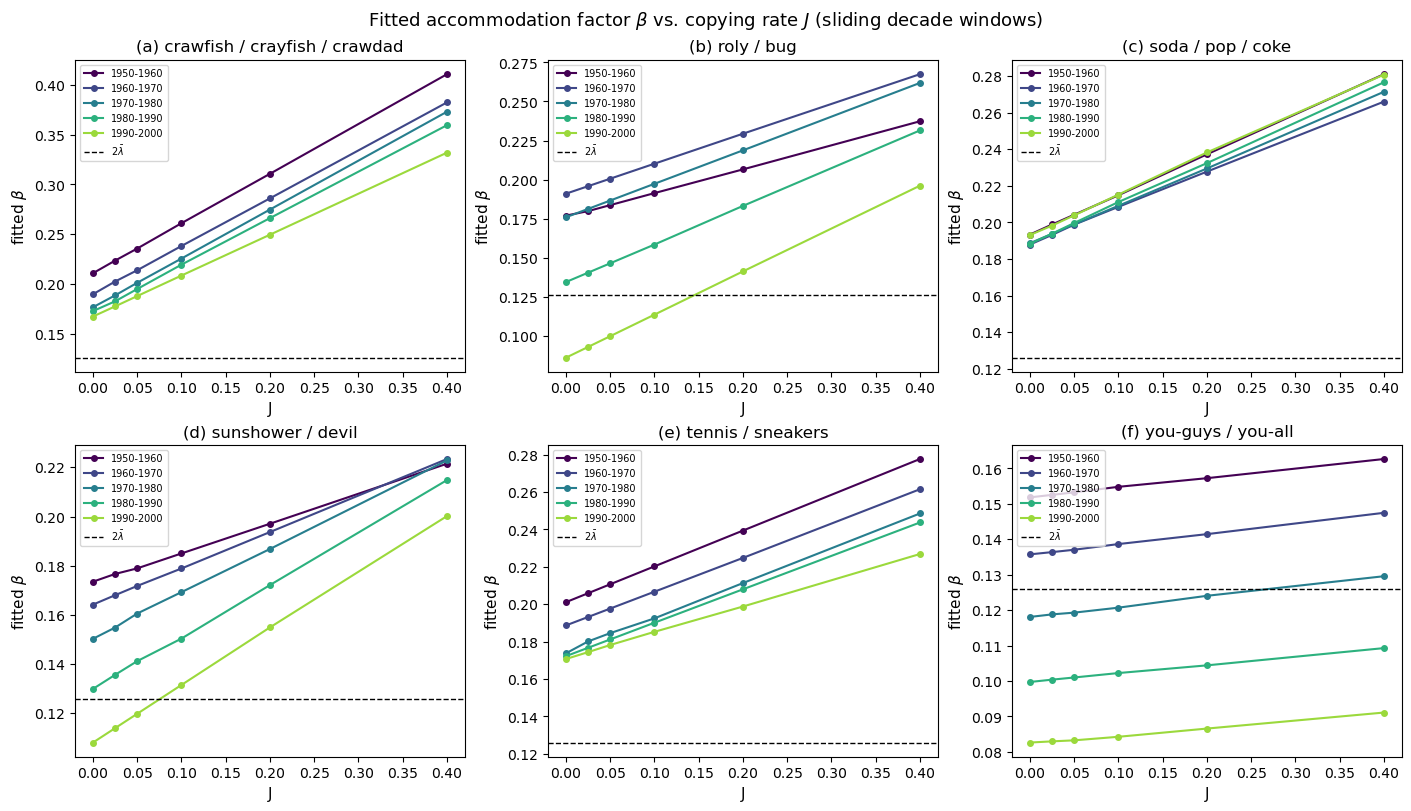

In [6]:
# Plot fitted beta vs J, one panel per variable, one line per decade
fig, axs = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
decade_colors = cm.viridis(np.linspace(0, 0.85, len(t0s)))

for idx, (key, label) in enumerate(var_order):
    ax = axs[idx // 3, idx % 3]
    res = scalarJ_results[key]
    for d, (t0, mid) in enumerate(zip(t0s, mid_years)):
        betas_d = [res[J]['beta'][d] for J in J_grid]
        ax.plot(J_grid, betas_d, '-o', color=decade_colors[d], markersize=4,
                label=f'{1950+t0}-{1950+t0+T_window}')
    ax.axhline(2 * lambda_bar, color='k', ls='--', lw=1, label=r'$2\bar\lambda$')
    ax.set_title(f'({chr(97+idx)}) {label}', fontsize=12)
    ax.set_xlabel('J', fontsize=11)
    ax.set_ylabel(r'fitted $\beta$', fontsize=11)
    ax.legend(fontsize=7, loc='upper left')

plt.suptitle(r'Fitted accommodation factor $\beta$ vs. copying rate $J$ (sliding decade windows)', fontsize=13)
plt.show()

**Observation:** the residual-minimising $\beta$ increases monotonically with $J$ for every
variable, as expected from the interface-width trade-off (eq. 4.3): increasing $J$ increases the
effective diffusion coefficient $D=JR^2/2$, and larger $\beta$ is needed to keep boundaries sharp
against the extra diffusive mixing. Note that for you-guys/you-all, fitted $\beta$ sits at or below the
stability threshold $2\bar\lambda\approx0.126$ for nearly the whole range of $J$ tested — consistent
with the paper's own observation (§4c, Fig. 9f/11f) that this variable shows weak spatial structure and
near-zero inferred bias; the model does not predict a stable interface for this variable regardless of
$J$.

## §2: In-sample fit quality vs. $J$

Does any value of $J$ stand out as optimising the Section 4 assimilation objective itself? We plot the
mean residual (objective value at the optimum, averaged over the five calibration decades).

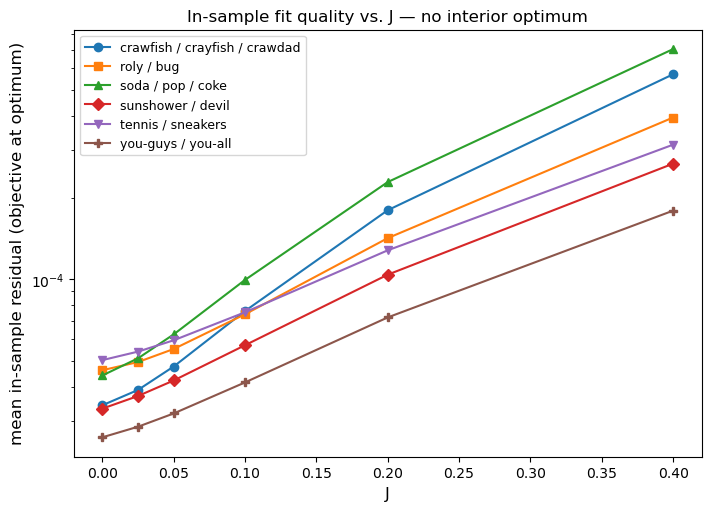

In [7]:
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
markers = ['o', 's', '^', 'D', 'v', 'P']
for i, (key, label) in enumerate(var_order):
    res = scalarJ_results[key]
    objs = [res[J]['obj'].mean() for J in J_grid]
    ax.plot(J_grid, objs, '-', marker=markers[i], label=label)

ax.set_yscale('log')
ax.set_xlabel('J', fontsize=12)
ax.set_ylabel('mean in-sample residual (objective at optimum)', fontsize=12)
ax.set_title('In-sample fit quality vs. J — no interior optimum', fontsize=12)
ax.legend(fontsize=9)
plt.show()

**Observation:** for every variable, the in-sample residual increases monotonically with $J$ —
smaller $J$ always fits the training decade better, by roughly an order of magnitude across the tested
range. There is no interior optimum. This confirms that $J$ cannot be selected by minimising the
Section 4 assimilation objective: with $N=4000$ cells, interface regions are a small fraction of the
domain, so bulk residual is dominated by non-boundary cells that are largely insensitive to $J$, while
being penalised by the mild diffusive smoothing $J$ introduces everywhere. Selecting $J$ this way would
always push toward $J\to0$, which — as §3 shows — predicts unrealistically sharp isoglosses.

## §3: Self-consistent interface width vs. $J$

For the four two-variant systems, eq. (4.3) gives the steady-state interface width
$w(D,\beta,\lambda)=\sqrt{D/(\beta-2\lambda)}$. Rather than assuming a fixed target width, we use each
$J$'s own **fitted** $\beta(J)$ from §1 to ask: what interface width does the model self-consistently
predict at that $J$? We compare this against the isogloss width actually documented in the paper for
tennis/sneakers — "two to three cells wide" (§4a), i.e. roughly 90–130 km given the mean cell diameter
of ~44 km.

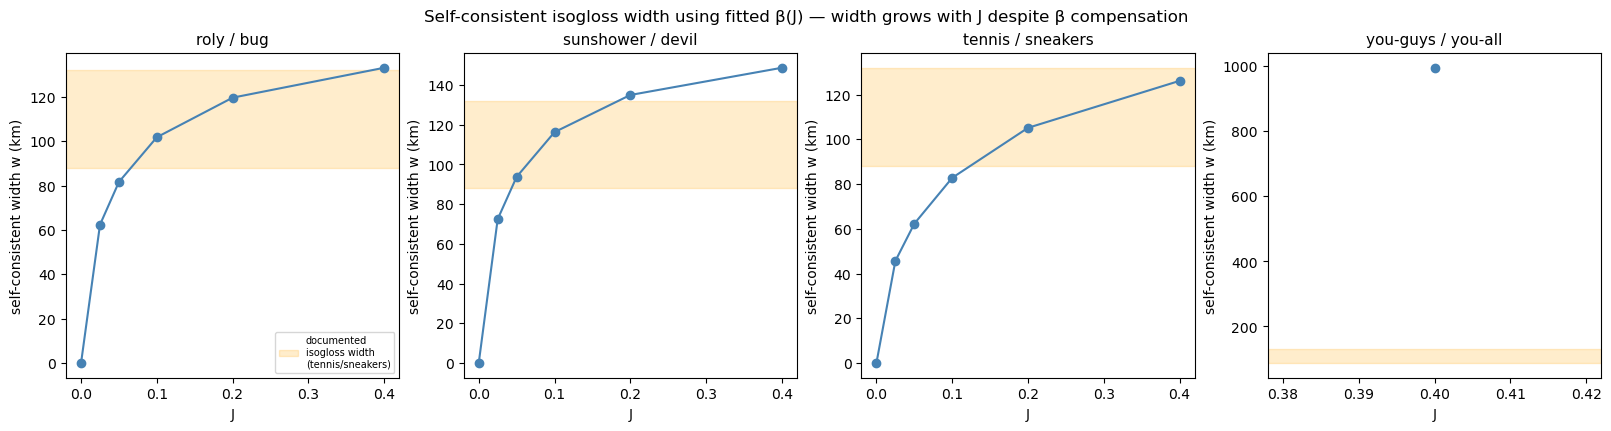

Self-consistent width w(J), km (nan = no stable interface predicted, β below 2λ):
roly / bug            J=0.0   w=   0.0  J=0.025 w=  62.4  J=0.05  w=  81.6  J=0.1   w= 101.8  J=0.2   w= 119.6  J=0.4   w= 133.1
sunshower / devil     J=0.0   w=   0.0  J=0.025 w=  72.4  J=0.05  w=  93.7  J=0.1   w= 116.2  J=0.2   w= 134.9  J=0.4   w= 148.6
tennis / sneakers     J=0.0   w=   0.0  J=0.025 w=  45.6  J=0.05  w=  62.3  J=0.1   w=  82.8  J=0.2   w= 105.1  J=0.4   w= 126.1
you-guys / you-all    J=0.0   w=  n/a   J=0.025 w=  n/a   J=0.05  w=  n/a   J=0.1   w=  n/a   J=0.2   w=  n/a   J=0.4   w= 994.7


In [8]:
cell_diam = 44.0  # km, mean cell diameter (Section 4a)
observed_band = (2 * cell_diam, 3 * cell_diam)  # documented tennis/sneakers isogloss width

fig, axs = plt.subplots(1, len(two_variant_keys), figsize=(16, 4.2), constrained_layout=True)

width_table = {}
for idx, key in enumerate(two_variant_keys):
    label = dict(var_order)[key]
    res = scalarJ_results[key]
    ax = axs[idx]
    widths = []
    for J in J_grid:
        beta_mean = res[J]['beta'].mean()
        diff = beta_mean - 2 * lambda_bar
        D = J * R**2 / 2
        w = np.sqrt(D / diff) if diff > 0 else np.nan
        widths.append(w)
    width_table[key] = dict(zip(J_grid, widths))

    ax.plot(J_grid, widths, 'o-', color='steelblue')
    ax.axhspan(*observed_band, color='orange', alpha=0.2, label='documented\nisogloss width\n(tennis/sneakers)')
    ax.set_title(f'{label}', fontsize=11)
    ax.set_xlabel('J', fontsize=10)
    ax.set_ylabel('self-consistent width w (km)', fontsize=10)
    if idx == 0:
        ax.legend(fontsize=7)

plt.suptitle('Self-consistent isogloss width using fitted β(J) — width grows with J despite β compensation', fontsize=12)
plt.show()

print('Self-consistent width w(J), km (nan = no stable interface predicted, β below 2λ):')
for key in two_variant_keys:
    label = dict(var_order)[key]
    line = f'{label:20s}'
    for J in J_grid:
        w = width_table[key][J]
        line += f'  J={J:<5} w={w:6.1f}' if not np.isnan(w) else f'  J={J:<5} w=  n/a '
    print(line)

**Observation:** fitted $\beta$ only partially compensates for increasing $J$ — self-consistent
width grows substantially across the tested range rather than staying fixed. For tennis/sneakers, only
$J\gtrsim0.1$ falls within the documented 2–3 cell isogloss width band; $J=0.025$ predicts an
implausibly sharp, single-cell boundary. This gives $J=0.1$ a principled empirical lower bound that has
nothing to do with the (monotonic, uninformative) assimilation residual of §2 — it comes from matching
an independently observed geographic feature of the data.

## §4: Forecasting skill vs. $J$ (out-of-sample)

We repeat the Section 4(b) forecast-horizon KL-divergence analysis (cf. Fig. 9, scalar-bias curves) for
several values of $J$, to see whether the paper's headline forecasting result is qualitatively preserved.

In [9]:
J_fwd       = [0.05, 0.1, 0.2, 0.4]
T_calib_kld = 10
T_fwd_kld   = 25
t_step_kld  = 5

pred_years  = np.arange(1, T_fwd_kld)
colors_J    = {0.05: '#4daf4a', 0.1: '#377eb8', 0.2: '#ff7f00', 0.4: '#e41a1c'}

fwd_results = {}
for key, label in var_order:
    P = variables[key]['P']; K = variables[key]['K']
    print(label)
    fwd_results[key] = {}
    for J in J_fwd:
        kld_sc = []
        t0 = 0
        while t0 + T_calib_kld + T_fwd_kld <= end_year - start_year:
            t1 = t0 + T_calib_kld; t2 = t1 + T_fwd_kld
            res_sc  = minimize(sm.make_objective(P, W, L, t0, t1, J), np.zeros(1 + K))
            beta_sc = res_sc.x[0]; s_sc = res_sc.x[1:]
            mod  = sm.model(W, L, J, np.tile(s_sc, (N, 1)), beta_sc, P[:, t1, :].copy())
            xsol = mod.solve(np.arange(T_fwd_kld + 1))
            kld_sc.append(sm.kld_time_series(P[:, t1:t2, :], xsol.transpose(1, 0, 2)[:, :T_fwd_kld, :]))
            t0 += t_step_kld
        fwd_results[key][J] = np.array(kld_sc)
        print(f'  J={J:<5} mean KLD at 10y={fwd_results[key][J][:,9].mean():.4f}  at 24y={fwd_results[key][J][:,23].mean():.4f}')

crawfish / crayfish / crawdad


  J=0.05  mean KLD at 10y=0.0184  at 24y=0.1561


  J=0.1   mean KLD at 10y=0.0260  at 24y=0.2190


  J=0.2   mean KLD at 10y=0.0486  at 24y=0.3677


  J=0.4   mean KLD at 10y=0.1197  at 24y=0.7195
roly / bug


...

  J=0.4   mean KLD at 10y=0.0287  at 24y=0.1221
you-guys / you-all


  J=0.05  mean KLD at 10y=0.0050  at 24y=0.0298


  J=0.1   mean KLD at 10y=0.0059  at 24y=0.0340


  J=0.2   mean KLD at 10y=0.0079  at 24y=0.0416


  J=0.4   mean KLD at 10y=0.0123  at 24y=0.0550


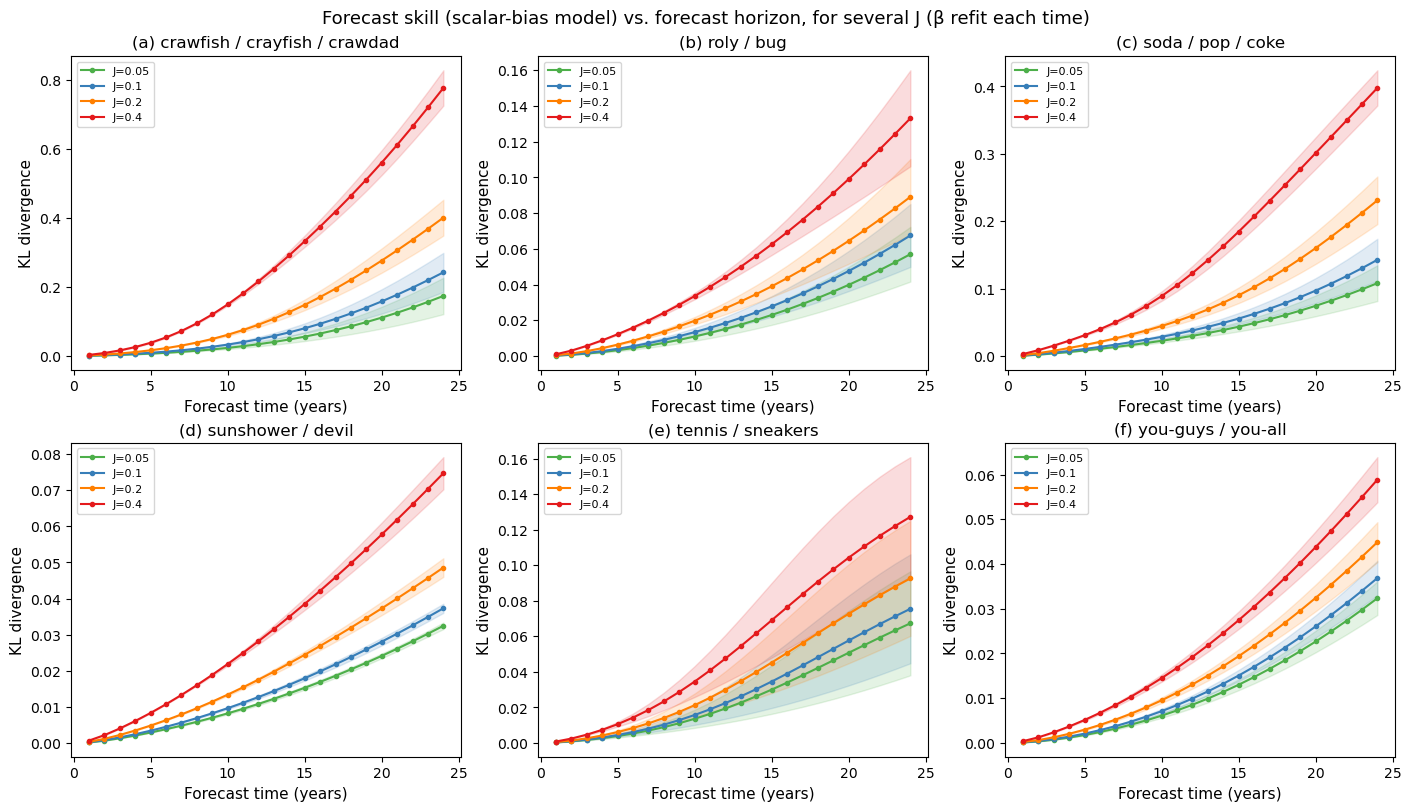

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)

for idx, (key, label) in enumerate(var_order):
    ax = axs[idx // 3, idx % 3]
    for J in J_fwd:
        arr = fwd_results[key][J]
        m, e = arr[:, 1:].mean(axis=0), arr[:, 1:].std(axis=0)
        ax.plot(pred_years, m, '-o', color=colors_J[J], label=f'J={J}', markersize=3)
        ax.fill_between(pred_years, m - e, m + e, color=colors_J[J], alpha=0.15)
    ax.set_title(f'({chr(97+idx)}) {label}', fontsize=12)
    ax.set_xlabel('Forecast time (years)', fontsize=11)
    ax.set_ylabel('KL divergence', fontsize=11)
    ax.legend(fontsize=8)

plt.suptitle('Forecast skill (scalar-bias model) vs. forecast horizon, for several J (β refit each time)', fontsize=13)
plt.show()

**Observation:** forecast KL-divergence increases monotonically with $J$ for every variable —
consistent with §2's in-sample finding — most noticeably for crawfish/crayfish/crawdad and soda/pop/coke
(roughly 3–5$\times$ worse at $J=0.4$ than $J=0.05$ at a 24-year horizon), and more mildly for the
remaining four variables (roughly 2$\times$). The *shape* and *relative ranking* of the forecast curves
(cf. Fig. 9) are preserved across this range — the qualitative conclusion that the model forecasts
reasonably well up to 10-15 years and degrades thereafter is robust to $J$ — but the absolute forecast
skill at a given $J$ should not be over-interpreted as evidence for that particular $J$, for the same
reason given in §2: forecast KLD is dominated by bulk cells and is essentially insensitive to whether
interface widths are realistic.

## Summary

1. **$\beta$ trades off against $J$** in the direction predicted by the interface-width formula (eq.
   4.3), but not enough to hold interface width fixed — self-consistent width grows with $J$ (§1, §3).
2. **Neither in-sample residual nor out-of-sample forecast KL-divergence has an interior optimum in
   $J$** — both improve monotonically as $J\to0$ (§2, §4). This means $J$ genuinely cannot be selected
   by the Section 4 assimilation objective, for a structural reason: interfaces occupy a small fraction
   of the domain, so bulk residual mostly reflects non-boundary cells that are not very sensitive to
   $J$.
3. **$J$ is instead identified by matching the empirically documented isogloss width** (§3): using each
   $J$'s own fitted $\beta$, only $J\gtrsim0.1$ predicts an interface width consistent with the observed
   tennis/sneakers isogloss (two to three cell diameters); smaller $J$ predicts implausibly sharp,
   sub-cell boundaries that are not seen in the data.
4. **Headline forecasting results are qualitatively robust to $J$** (§4): forecast curves preserve their
   shape and relative ranking across the tested range, though absolute forecast skill is somewhat worse
   at larger $J$ — an expected consequence of (2), not evidence against the model.
5. **you-guys/you-all is a genuine limit case**: fitted $\beta$ sits at or below the stability threshold
   $2\bar\lambda$ for nearly all $J$ tested, so the model does not predict a stable interface for this
   variable — consistent with the paper's existing observation that this variable shows weak spatial
   structure and near-zero inferred bias (Fig. 9f, Fig. 11f).

**Conclusion for the response to reviewers:** $J=0.1$ was never intended to optimise the Section 4
fitting objective (which, as shown here, favours $J\to0$ for reasons unrelated to isogloss realism).
It was chosen — and should be described as chosen — to match the independently observed width of real
dialect boundaries, a criterion the fitting objective cannot see. This is a precise, falsifiable
selection criterion, not an aesthetic preference.